In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

Sélection des actifs

In [ ]:
print ("================= Welcome to the Portfolio Risk Engine!=====================")
print ()
print ("Please enter the tickers of your portfolio assets (separated by commas):")
actif1 = input('Enter the first asset ticker: ')
actif2 = input('Enter the second asset ticker: ')
actif3 = input('Enter the third asset ticker: ')
actif4 = input('Enter the fourth asset ticker: ')
actif5 = input('Enter the fifth asset ticker: ')
actif6 = input('Enter the sixth asset ticker: ')

================= Welcome to the Portfolio Risk Engine!=====================

Please enter the tickers of your portfolio assets (separated by commas):


In [4]:
tickers = ('AAPL', 'JPM','JNJ','AMZN','PG','NEE','CAT','AMT','GLD')
data = yf.download (tickers, start='2020-01-01', end='2025-12-31')['Close']
data = pd.DataFrame(data).dropna()
data

[*********************100%***********************]  9 of 9 completed


Ticker,AAPL,AMT,AMZN,CAT,GLD,JNJ,JPM,NEE,PG
Date,,,,,,,,,
2020-01-02,72.271545,187.878418,94.900497,132.067856,143.949997,121.338509,117.313927,50.335987,103.959297
2020-01-03,71.568909,187.968842,93.748497,130.234192,145.860001,119.933708,115.765823,50.694592,103.260117
2020-01-06,72.139191,187.919525,95.143997,130.146469,147.389999,119.784081,115.673752,50.947739,103.403336
2020-01-07,71.799904,183.915283,95.343002,128.426865,147.970001,120.515587,113.707237,50.903431,102.763115
2020-01-08,72.954918,185.510422,94.598503,129.567413,146.860001,120.498955,114.594231,50.880230,103.201141
...,...,...,...,...,...,...,...,...,...
2025-12-23,271.620667,167.687546,232.139999,578.882446,413.640015,202.522552,319.771271,78.086189,140.062469
2025-12-24,273.066711,167.966232,232.380005,580.214355,411.929993,204.490875,322.950073,78.732094,141.343964
2025-12-26,272.657806,169.513290,232.520004,579.458984,416.739990,204.343246,321.713898,78.692955,141.588501


Poids des actifs

In [5]:
w1 = float(input(f'Enter the weight of {actif1}: '))
w2 = float(input(f'Enter the weight of {actif2}: '))
w3 = float(input(f'Enter the weight of {actif3}: '))
w4 = float(input(f'Enter the weight of {actif4}: '))
w5 = float(input(f'Enter the weight of {actif5}: '))
w6 = float(input(f'Enter the weight of {actif6}: '))

if w1 + w2 + w3 + w4 + w5 + w6 != 1:
    print("Error: The sum of the weights must be equal to 1.")

NameError: name 'actif1' is not defined

Calcul du rendement du portefeuille

In [29]:
data_returns = data.pct_change().dropna()
assets_returns = data_returns.mean (axis=0)
print (assets_returns)


Ticker
AAPL    0.001081
AMT     0.000114
AMZN    0.000848
CAT     0.001184
GLD     0.000730
JNJ     0.000420
JPM     0.000856
NEE     0.000477
PG      0.000286
dtype: float64


In [30]:
portfolio_weights = np.array([0.15, 0.1, 0.2, 0.1, 0.2, 0.1, 0.05, 0.05, 0.05])  # Example weights for the assets
portfolio = pd.DataFrame ({'Assets': data.columns, 'Returns': assets_returns, 'Weights': portfolio_weights})

In [8]:
portfolio_returns = portfolio['Returns']*portfolio['Weights']
print(f"Expected Portfolio Return: {portfolio_returns.sum():.4f}")

Expected Portfolio Return: 0.0007


Monte Carlo VaR

In [ ]:
def simulation_gbm (weights, returns, cov, S0 = 1.0, n_days = 252, n_sim = 10000) : 
    np.random.seed (42)
    dt = 1/252
    
    port_values = np.zeros ((n_sim, n_days+1))
    port_values [:,0] = S0

    for t in range (1, n_days + 1) :
        asset_returns = (returns - 0.5 * np.diag(cov)) * dt + np.diag(cov) * np.sqrt (dt)
        port_return = asset_returns @ weights     
        port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

    return port_values

In [36]:
simulated_portfolio_values = simulation_gbm (portfolio_weights, assets_returns, data_returns.cov())
print (simulated_portfolio_values)

[[1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]
 [1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]
 [1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]
 ...
 [1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]
 [1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]
 [1.         1.00002245 1.00004491 ... 1.00562935 1.00565193 1.00567452]]


In [48]:
simulated_portfolio_values [0].shape

(253,)

AttributeError: 'int' object has no attribute 'T'

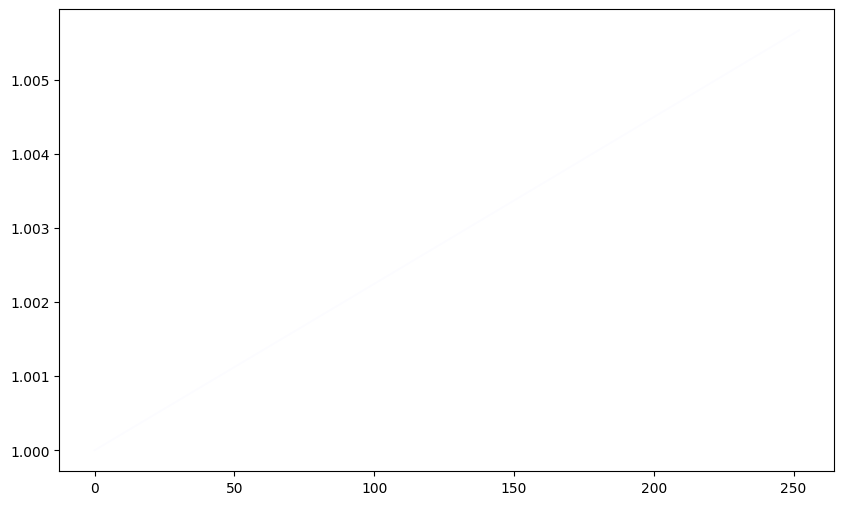

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(simulated_portfolio_values[0].T, color='blue', alpha=0.01)
for i in range(simulated_portfolio_values.shape):
   plt.plot(simulated_portfolio_values[i], alpha=0.01)
plt.title('Simulated Portfolio Value Paths')
plt.xlabel('Days')
plt.ylabel('Portfolio Value')
plt.show()

In [34]:
port_values = np.zeros ((10, 91))
port_values [:,0] = 1.0    #n_sim simulations de la valeur de l'actif sur n_days

#print (port_values)
#asset_ret = (assets_returns - 0.5 * np.diag(data_returns.cov())) * 1/252 + np.diag(data_returns.cov()) * np.sqrt (1/252)
port_return = asset_ret @ portfolio_weights
#port_values [:,2] = port_values [:, 1] * np.exp (port_return)

for t in range (1,91) : 
    asset_ret = (assets_returns - 0.5 * np.diag(data_returns.cov())) * (1/252) + np.diag(data_returns.cov()) * np.sqrt (1/252)
    port_return = asset_ret @ portfolio_weights
    port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

print (asset_ret)
print (port_values)

Ticker
AAPL    0.000029
AMT     0.000022
AMZN    0.000034
CAT     0.000030
GLD     0.000009
JNJ     0.000011
JPM     0.000027
NEE     0.000024
PG      0.000011
dtype: float64
[[1.         1.00002245 1.00004491 1.00006737 1.00008982 1.00011228
  1.00013473 1.00015719 1.00017965 1.00020211 1.00022457 1.00024703
  1.00026949 1.00029195 1.00031441 1.00033687 1.00035933 1.0003818
  1.00040426 1.00042672 1.00044919 1.00047165 1.00049412 1.00051658
  1.00053905 1.00056151 1.00058398 1.00060645 1.00062892 1.00065139
  1.00067386 1.00069632 1.00071879 1.00074127 1.00076374 1.00078621
  1.00080868 1.00083115 1.00085363 1.0008761  1.00089857 1.00092105
  1.00094352 1.000966   1.00098848 1.00101095 1.00103343 1.00105591
  1.00107839 1.00110086 1.00112334 1.00114582 1.0011683  1.00119078
  1.00121327 1.00123575 1.00125823 1.00128071 1.0013032  1.00132568
  1.00134816 1.00137065 1.00139313 1.00141562 1.00143811 1.00146059
  1.00148308 1.00150557 1.00152806 1.00155055 1.00157303 1.00159552
  1.001618

In [33]:
data_returns.var()

Ticker
AAPL    0.000402
AMT     0.000350
AMZN    0.000506
CAT     0.000417
GLD     0.000106
JNJ     0.000153
JPM     0.000391
NEE     0.000357
PG      0.000169
dtype: float64

In [ ]:
print (simulated_portfolio_values [-1])

[1.00000000e+000 1.33819450e+074 1.79076453e+148 2.39639125e+222
 3.20683760e+296             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf             inf             inf             inf
             inf         

In [ ]:
ret = np.array(assets_returns.values)

asset_ret = (ret - 0.5 * np.diag(data.cov())) * (1/252) + np.diag(data.cov()) * np.sqrt (1/252)
asset_ret = (assets_returns - 0.5 * np.diag(data.cov()))
print (asset_ret)


Ticker
AAPL   -1226.309139
AMT     -254.510223
AMZN    -798.536714
CAT    -5706.534145
GLD    -1689.337245
JNJ     -125.137677
JPM    -1971.597216
NEE      -35.009557
PG      -166.783701
dtype: float64
